# TP5 - Punto 5
## Modelo depredador-presa de Lotka-Volterra

In [1]:
from pathlib import Path
import os

os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd() / ".mplconfig"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 4.8)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

def mostrar_tabla(df, decimales=4):
    display(df.round(decimales).style.hide(axis="index"))

def lotka_volterra_rhs(alpha, beta, delta, gamma):
    def f(t, z):
        x, y = z
        return [alpha * x - beta * x * y, delta * x * y - gamma * y]
    return f

def resolver_lotka_volterra(alpha=1, beta=0.1, delta=0.075, gamma=1.5, x0=10, y0=5, t_final=30, n=2000):
    t_eval = np.linspace(0, t_final, n)
    sol = solve_ivp(
        lotka_volterra_rhs(alpha, beta, delta, gamma),
        t_span=(0, t_final),
        y0=[x0, y0],
        t_eval=t_eval,
        rtol=1e-9,
        atol=1e-12,
    )
    if not sol.success:
        raise RuntimeError(sol.message)
    return sol.t, sol.y[0], sol.y[1]

def estimar_periodo_desde_picos(t, x):
    picos, _ = find_peaks(x)
    if len(picos) < 2:
        return np.nan, picos
    return np.mean(np.diff(t[picos])), picos

## 5. Modelo depredador-presa de Lotka-Volterra

El modelo de Lotka-Volterra describe la interaccion entre dos poblaciones:

`dx/dt = alpha*x - beta*x*y`

`dy/dt = delta*x*y - gamma*y`

Donde:

- `x(t)` representa las presas.
- `y(t)` representa los depredadores.
- `alpha*x`: las presas solas crecen como Malthus, igual que en el punto 2.
- `-beta*x*y`: las presas mueren al encontrarse con depredadores. Es un producto porque hacen falta presas y depredadores.
- `delta*x*y`: los depredadores crecen gracias a lo que comen.
- `-gamma*y`: los depredadores sin comida decaen como el decaimiento radioactivo, igual que en el punto 3.

El modelo combina Malthus y decaimiento radioactivo, conectados por el termino de encuentro `x*y`.

El termino `x*y` hace que el sistema sea no lineal. Por eso no se resuelve con una formula cerrada simple como en los puntos 1 a 3, sino numericamente.

### Diagrama en bloques en Xcos

El punto se resolvio principalmente con un diagrama en bloques en Xcos.

![Diagrama y simulacion Xcos del caso base](CapturasXcos/5-caso-base.png)

La estructura del diagrama es:

- Un integrador por variable. La salida del integrador es la variable, y la entrada es su derivada.
- Un bloque `PRODUCT` calcula `x*y` una sola vez y reparte ese resultado a los dos sumadores.
- Las ganancias representan los parametros del modelo.
- Los sumadores arman `dx/dt` y `dy/dt`.
- Los scopes muestran las curvas temporales y el plano de fases.

En Xcos los parametros se definieron como `a`, `b`, `d` y `g`, que corresponden a `alpha`, `beta`, `delta` y `gamma`. Se uso esta notacion porque `beta` y `gamma` son nombres de funciones propias de Scilab.

| Bloque | Funcion en el modelo |
|---|---|
| `INTEGRAL_m` | Integra cada derivada para obtener `x(t)` e `y(t)`. |
| `PRODUCT` | Calcula el producto `x*y`, que representa el encuentro entre presas y depredadores. |
| `GAINBLK` | Multiplica las señales por los parametros `a`, `b`, `d` y `g`. |
| `BIGSOM_f` | Suma los terminos para construir cada derivada. |
| `CMSCOPE` | Muestra las curvas temporales `x(t)` e `y(t)`. |
| `CSCOPXY` | Muestra el plano de fases, es decir `y` contra `x`. |
| `CLOCK_c` | Define el paso de muestreo de los graficos. |

### Caso base en Xcos

Se uso el siguiente conjunto de parametros:

| Parametro | Valor | Interpretacion |
|---|---:|---|
| `alpha` | `1` | crecimiento natural de las presas |
| `beta` | `0.1` | efecto de los depredadores sobre las presas |
| `delta` | `0.075` | crecimiento de depredadores por consumo de presas |
| `gamma` | `1.5` | mortalidad natural de depredadores |
| `x(0)` | `10` | presas iniciales |
| `y(0)` | `5` | depredadores iniciales |
| tiempo final | `30` | duracion de la simulacion |
| paso del reloj | `0.01` | paso usado para graficar en Xcos |

En la captura, el grafico temporal muestra arriba `x(t)` y abajo `y(t)`. La etiqueta `y` del eje vertical es generica de Xcos.

Tambien se muestra el plano de fases `y` contra `x`. En ese grafico, una curva cerrada indica que el sistema vuelve al mismo estado y repite el ciclo.

La interpretacion del caso base es:

1. Hay muchas presas.
2. Aumentan los depredadores porque tienen alimento.
3. Bajan las presas por la depredacion.
4. Bajan los depredadores porque queda menos alimento.
5. Las presas se recuperan y el ciclo vuelve a empezar.

Los picos de depredadores aparecen despues de los picos de presas. Esto tiene sentido: primero aumenta la comida y despues responde la poblacion depredadora.

### Punto de equilibrio

Para encontrar el equilibrio se igualan las derivadas a cero:

`dx/dt = 0`

`dy/dt = 0`

Del sistema:

`dx/dt = alpha*x - beta*x*y = x(alpha - beta*y)`

`dy/dt = delta*x*y - gamma*y = y(delta*x - gamma)`

El equilibrio no trivial queda:

`x* = gamma / delta`

`y* = alpha / beta`

Con los parametros del caso base:

`x* = 1.5 / 0.075 = 20`

`y* = 1 / 0.1 = 10`

Entonces el ciclo gira alrededor del punto `(20, 10)`. Tambien existe el equilibrio trivial `(0, 0)`.

Este equilibrio cumple un rol parecido a `Tamb` en Newton: es un estado en el que el sistema no cambia.

### Validacion con Python

La resolucion principal se hizo en Xcos. Python se usa solo para validar que el diagrama este bien armado.

Como no hay solucion analitica simple para comparar, se simula el mismo sistema con `solve_ivp`. Si Xcos y Python muestran el mismo comportamiento, la implementacion en bloques es consistente.

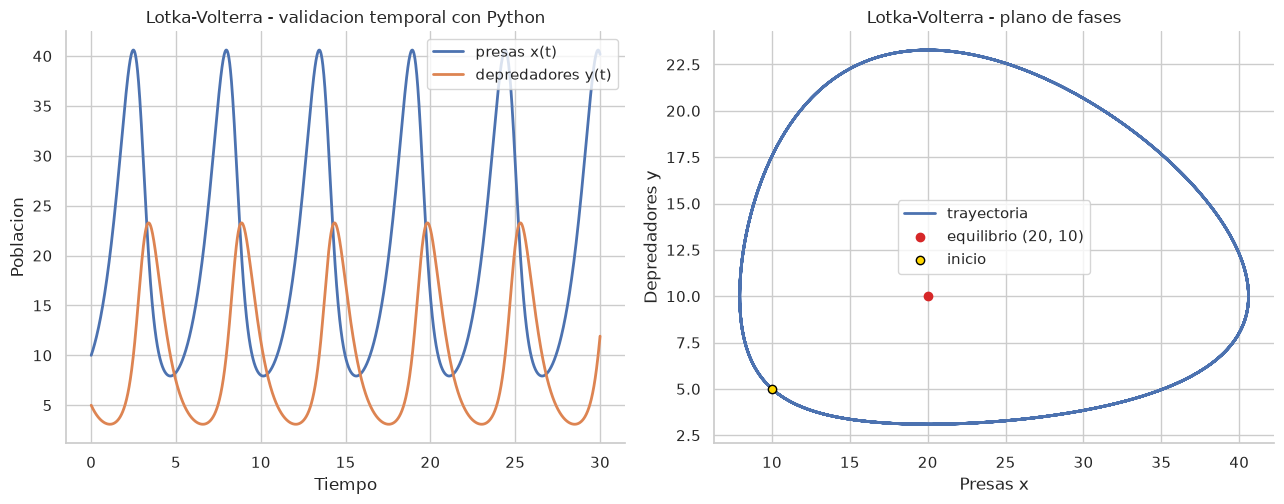

x minimo,x maximo,y minimo,y maximo,periodo aproximado,equilibrio x*,equilibrio y*
7.925600,40.597900,3.092400,23.277800,5.477700,20.000000,10.000000


In [2]:
alpha = 1
beta = 0.1
delta = 0.075
gamma = 1.5
x0 = 10
y0 = 5
t_final = 30

t, x, y = resolver_lotka_volterra(alpha, beta, delta, gamma, x0, y0, t_final)
x_equilibrio = gamma / delta
y_equilibrio = alpha / beta
periodo_aprox, picos_x = estimar_periodo_desde_picos(t, x)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

axes[0].plot(t, x, linewidth=2, label="presas x(t)")
axes[0].plot(t, y, linewidth=2, label="depredadores y(t)")
axes[0].set_title("Lotka-Volterra - validacion temporal con Python")
axes[0].set_xlabel("Tiempo")
axes[0].set_ylabel("Poblacion")
axes[0].legend()

axes[1].plot(x, y, linewidth=2, label="trayectoria")
axes[1].scatter([x_equilibrio], [y_equilibrio], color="tab:red", zorder=5, label=f"equilibrio ({x_equilibrio:.0f}, {y_equilibrio:.0f})")
axes[1].scatter([x0], [y0], color="gold", edgecolor="black", zorder=5, label="inicio")
axes[1].set_title("Lotka-Volterra - plano de fases")
axes[1].set_xlabel("Presas x")
axes[1].set_ylabel("Depredadores y")
axes[1].legend()

plt.tight_layout()
plt.show()

resumen_base = pd.DataFrame([{
    "x minimo": np.min(x),
    "x maximo": np.max(x),
    "y minimo": np.min(y),
    "y maximo": np.max(y),
    "periodo aproximado": periodo_aprox,
    "equilibrio x*": x_equilibrio,
    "equilibrio y*": y_equilibrio,
}])

mostrar_tabla(resumen_base)

La validacion muestra el mismo comportamiento que Xcos: las poblaciones oscilan y el plano de fases forma una curva cerrada alrededor del equilibrio `(20, 10)`.

La curva cerrada indica que el ciclo se repite. El periodo aproximado se calcula en Python midiendo la distancia promedio entre picos consecutivos de `x(t)`.

### Casos especiales

En estos casos se comparan las capturas de Xcos con una simulacion equivalente en Python. La resolucion principal sigue siendo el diagrama en bloques; Python se usa para validar y medir algunos valores.

In [ ]:
parametros_base = {
    "alpha": 1,
    "beta": 0.1,
    "delta": 0.075,
    "gamma": 1.5,
}

def graficar_caso_lotka(titulo, alpha=1, beta=0.1, delta=0.075, gamma=1.5, x0=10, y0=5, t_final=30):
    t, x, y = resolver_lotka_volterra(alpha, beta, delta, gamma, x0, y0, t_final)
    x_equilibrio = gamma / delta
    y_equilibrio = alpha / beta

    fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

    axes[0].plot(t, x, linewidth=2, label="presas x(t)")
    axes[0].plot(t, y, linewidth=2, label="depredadores y(t)")
    axes[0].set_title(titulo + " - temporal")
    axes[0].set_xlabel("Tiempo")
    axes[0].set_ylabel("Poblacion")
    axes[0].legend()

    axes[1].plot(x, y, linewidth=2, label="trayectoria")
    axes[1].scatter([x_equilibrio], [y_equilibrio], color="tab:red", s=70, zorder=5, label=f"equilibrio ({x_equilibrio:.0f}, {y_equilibrio:.0f})")
    axes[1].scatter([x0], [y0], color="gold", edgecolor="black", s=60, zorder=6, label="inicio")
    axes[1].set_title(titulo + " - plano de fases")
    axes[1].set_xlabel("Presas x")
    axes[1].set_ylabel("Depredadores y")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

    return t, x, y

#### Caso 1: arrancar en el equilibrio

Condiciones: `x(0) = 20`, `y(0) = 10`, con parametros base.

![Xcos caso 1](img/p5_caso1.png)

In [ ]:
t_c1, x_c1, y_c1 = graficar_caso_lotka(
    "Caso 1: equilibrio",
    x0=20,
    y0=10,
)

mostrar_tabla(pd.DataFrame([{
    "x inicial": x_c1[0],
    "x final": x_c1[-1],
    "y inicial": y_c1[0],
    "y final": y_c1[-1],
    "max |x - 20|": np.max(np.abs(x_c1 - 20)),
    "max |y - 10|": np.max(np.abs(y_c1 - 10)),
}]))

Observado en Xcos: `x` queda constante en `20` e `y` queda constante en `10` durante toda la simulacion.

El grafico XY de Xcos queda vacio porque el scope dibuja lineas uniendo puntos consecutivos. Como el sistema no se mueve, la linea tiene largo cero. En Python se marco el punto `(20, 10)` con un marcador para que se vea.

Interpretacion: es el punto de equilibrio. Las dos derivadas valen `0` y nada cambia. Es el equivalente a `T0 = Tamb` en Newton.

#### Caso 2: arrancar cerca del equilibrio

Condiciones: `x(0) = 18`, `y(0) = 9`, con parametros base.

![Xcos caso 2](img/p5_caso2.png)

In [ ]:
t_base, x_base, y_base = resolver_lotka_volterra(**parametros_base, x0=10, y0=5, t_final=30)
periodo_base, _ = estimar_periodo_desde_picos(t_base, x_base)

t_c2, x_c2, y_c2 = graficar_caso_lotka(
    "Caso 2: cerca del equilibrio",
    x0=18,
    y0=9,
)
periodo_caso2, _ = estimar_periodo_desde_picos(t_c2, x_c2)
periodo_teorico_chico = 2 * np.pi / np.sqrt(parametros_base["alpha"] * parametros_base["gamma"])

mostrar_tabla(pd.DataFrame([
    {"medicion": "periodo caso base", "valor": periodo_base},
    {"medicion": "periodo caso 2", "valor": periodo_caso2},
    {"medicion": "periodo teorico oscilaciones chicas", "valor": periodo_teorico_chico},
]))

Observado en Xcos: aparecen oscilaciones chicas alrededor de `20` y `10`. En el plano XY se ve un ciclo casi eliptico alrededor del equilibrio `(20, 10)`.

Interpretacion: el tamaño del ciclo depende de que tan lejos del equilibrio se arranca. Cada condicion inicial tiene su propio ciclo cerrado y el sistema se queda en el para siempre.

Cerca del equilibrio las oscilaciones son casi sinusoidales y mas rapidas. En Python, el periodo del caso 2 queda muy cerca del periodo teorico para oscilaciones chicas, `2*pi/sqrt(alpha*gamma)`.

#### Caso 3: sin depredadores

Condiciones: `x(0) = 10`, `y(0) = 0`, con tiempo final `5`.

![Xcos caso 3](img/p5_caso3.png)

In [ ]:
t_c3, x_c3, y_c3 = graficar_caso_lotka(
    "Caso 3: sin depredadores",
    x0=10,
    y0=0,
    t_final=5,
)
x5_formula = 10 * np.exp(parametros_base["alpha"] * 5)

mostrar_tabla(pd.DataFrame([{
    "x(5) Python": x_c3[-1],
    "10*e^5": x5_formula,
    "y(5) Python": y_c3[-1],
    "diferencia x": abs(x_c3[-1] - x5_formula),
}]))

Observado en Xcos: `x` crece exponencialmente hasta aproximadamente `1480` en `t = 5`, mientras `y` queda en `0`. En el plano XY se ve una linea horizontal sobre `y = 0`.

Interpretacion: con `y = 0`, el termino `x*y` desaparece y queda `dx/dt = alpha*x`. Eso es Malthus, como en el punto 2, con `r = alpha = 1`.

Python verifica que `x(5) = 10*e^5`, aproximadamente `1484`. Los depredadores nunca aparecen porque `dy/dt = 0`, igual que el caso `P0 = 0` en Malthus.

Este caso muestra el supuesto de alimento ilimitado para las presas. En la realidad, el crecimiento se frenaria y haria falta un modelo logistico.

#### Caso 4: sin presas

Condiciones: `x(0) = 0`, `y(0) = 5`, con tiempo final `5`.

![Xcos caso 4](img/p5_caso4.png)

In [ ]:
t_c4, x_c4, y_c4 = graficar_caso_lotka(
    "Caso 4: sin presas",
    x0=0,
    y0=5,
    t_final=5,
)
vida_media_dep = np.log(2) / parametros_base["gamma"]
y5_formula = 5 * np.exp(-parametros_base["gamma"] * 5)

mostrar_tabla(pd.DataFrame([{
    "vida media ln(2)/gamma": vida_media_dep,
    "y(5) Python": y_c4[-1],
    "5*e^(-1.5*5)": y5_formula,
    "x(5) Python": x_c4[-1],
}]))

Observado en Xcos: `y` decae exponencialmente de `5` a casi `0`, y `x` queda en `0`. En el plano XY se ve una linea vertical sobre `x = 0` que baja.

Interpretacion: con `x = 0`, el termino `x*y` desaparece y queda `dy/dt = -gamma*y`. Eso es el decaimiento radioactivo del punto 3, con `lambda = gamma = 1.5`.

La vida media es `ln(2)/gamma`, aproximadamente `0.46` unidades de tiempo.

Nota sobre la captura: en el scope de Xcos la curva arranca un poco despues de `t = 0` y se ve cerca de `4.3` en lugar de `5`. Es una particularidad de como dibuja el scope el primer tramo, no un error de la simulacion.

**Relacion entre los casos 3 y 4.**

Lotka-Volterra es Malthus para las presas mas decaimiento para los depredadores, conectados por el termino `x*y`.

Si se quita una especie, el termino de encuentro desaparece y cada poblacion vuelve a su modelo simple: las presas crecen como Malthus y los depredadores decaen como una sustancia radioactiva.

#### Caso 5: depredadores mas fragiles

Condiciones: `gamma = 3`, `x(0) = 10`, `y(0) = 5`, con tiempo final `40`.

![Xcos caso 5](img/p5_caso5.png)

In [ ]:
t_c5, x_c5, y_c5 = graficar_caso_lotka(
    "Caso 5: gamma = 3",
    gamma=3,
    x0=10,
    y0=5,
    t_final=40,
)
periodo_caso5, picos_c5 = estimar_periodo_desde_picos(t_c5, x_c5)

mostrar_tabla(pd.DataFrame([{
    "x minimo": np.min(x_c5),
    "x maximo": np.max(x_c5),
    "y minimo": np.min(y_c5),
    "y maximo": np.max(y_c5),
    "periodo aproximado": periodo_caso5,
    "cantidad de picos de x": len(picos_c5),
    "equilibrio x*": 3 / parametros_base["delta"],
    "equilibrio y*": parametros_base["alpha"] / parametros_base["beta"],
}]))

Observado en Xcos: las presas oscilan entre aproximadamente `9` y `108`, y los depredadores entre casi `0` y `46`. El periodo es aproximadamente `4.5`, con unos `9` ciclos en `40` unidades de tiempo. En el plano XY se ve un ciclo grande alrededor de `(40, 10)`.

Interpretacion: al aumentar `gamma`, los depredadores son mas fragiles. Por eso el equilibrio se mueve a `x* = gamma/delta = 40`: hacen falta mas presas para sostenerlos. En cambio `y* = alpha/beta = 10` no cambia porque no depende de `gamma`.

Los picos son bruscos: hay periodos largos con poblaciones bajas y despues crecimientos repentinos. Es un ciclo de auge y caida.

Python da un minimo de depredadores menor que `1` individuo. El modelo los recupera porque trata la poblacion como continua, pero en la realidad esa poblacion probablemente se habria extinguido. Es el mismo supuesto que falla en Malthus con poblaciones chicas.

### Resumen de casos especiales

La tabla resume que se observa en cada caso y como se relaciona con los puntos anteriores.

In [ ]:
tabla_resumen_casos = pd.DataFrame([
    {
        "caso": "1",
        "condiciones": "x(0)=20, y(0)=10",
        "comportamiento observado": "constantes, sin ciclo",
        "relacion con otros puntos": "equilibrio, como T0 = Tamb en Newton",
    },
    {
        "caso": "2",
        "condiciones": "x(0)=18, y(0)=9",
        "comportamiento observado": "ciclo chico casi eliptico, mas rapido",
        "relacion con otros puntos": "el tamaño del ciclo depende de la condicion inicial",
    },
    {
        "caso": "3",
        "condiciones": "y(0)=0",
        "comportamiento observado": "presas crecen exponencialmente",
        "relacion con otros puntos": "Malthus, punto 2",
    },
    {
        "caso": "4",
        "condiciones": "x(0)=0",
        "comportamiento observado": "depredadores decaen exponencialmente",
        "relacion con otros puntos": "decaimiento radioactivo, punto 3",
    },
    {
        "caso": "5",
        "condiciones": "gamma=3",
        "comportamiento observado": "equilibrio en (40, 10), ciclo grande y brusco, periodo menor",
        "relacion con otros puntos": "depredadores bajan a menos de 1 individuo",
    },
])

display(
    tabla_resumen_casos.style.hide(axis="index").set_properties(
        subset=["comportamiento observado", "relacion con otros puntos"],
        **{"white-space": "normal", "text-align": "left"}
    )
)

### Supuestos del modelo

El modelo de Lotka-Volterra supone:

- Las presas tienen alimento ilimitado. Sin depredadores, crecen sin limite.
- Los depredadores solo comen esa presa.
- Los parametros son constantes.
- Las poblaciones son continuas y grandes.
- No hay migracion ni otras especies.

La hipotesis de poblaciones continuas es importante. Si en algun ciclo una poblacion baja mucho, el modelo puede dar fracciones de individuos. En la realidad, con pocos individuos podria ocurrir extincion, igual que pasaba en Malthus.

**Conclusion del punto 5.**

Lotka-Volterra combina Malthus y el decaimiento radioactivo, conectados por el termino de encuentro `x*y`.

Ese termino hace que el sistema sea no lineal y no tenga una solucion analitica simple. Por eso se resuelve numericamente con el diagrama en bloques y se valida con Python.

En el caso base, las poblaciones oscilan en ciclos que se repiten. Los depredadores aparecen atrasados respecto de las presas: primero aumenta la comida y despues aumenta la poblacion depredadora.

El ciclo gira alrededor de un equilibrio que depende de los parametros:

`x* = gamma/delta`

`y* = alpha/beta`